# Étape 3 : construire et valider le compte officiel

**Question.** Combien de voyageurs montent chaque jour, dans chaque gare, sur chaque ligne et
dans chaque tranche horaire, y compris les jours où la SNCF n'a rien compté ?

**Ce que disent les données (étape 2).** La SNCF publie des comptages *ponctuels* : environ
quatre journées par gare et par ligne, réparties depuis 2019. IDFM publie les validations
*de tous les jours* de chaque zone, mais tous modes confondus et avec plusieurs mois de retard.
Le compte officiel combine les deux, avec une hiérarchie transparente :

| Niveau | Méthode | Quand | Formule |
|---|---|---|---|
| 1 | `MESURE` | la SNCF a compté cette tranche, sans erreur qualité | somme des comptages |
| 2 | `CORRIGE_OFFRE` | train supprimé | *non applicable : pas de numéro de train dans les comptages* |
| 3 | `RECONCILIE_IDFM` | validations IDFM publiées pour ce jour | α × validations du jour × part de la tranche |
| 4 | `EXTRAPOLE` | pas encore de validations publiées | α × validations attendues × part de la tranche |

Ce notebook justifie chaque choix par une mesure : le facteur α, le profil horaire, la
modulation journalière, la météo, puis l'erreur obtenue en validation croisée.

```bash
git clone --branch data --single-branch https://github.com/quen9669/Comptage-Train-FR.git data
pip install -e ".[notebooks]"
comptage qualify && comptage compte-officiel      # si data/gold n'est pas à jour
jupyter lab notebooks/02_compte_officiel.ipynb
```

> Uniquement des données Open Data publiques (SNCF, Île-de-France Mobilités, Open-Meteo).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comptage_train import gold, silver, warehouse
from comptage_train.settings import data_dir

DATA = data_dir()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

con = warehouse.connect_derived(DATA)
gold.build_gold(con, str(pd.Timestamp.today().date()))   # recalcule gold et ses tables de travail
sql = lambda q: con.execute(q).df()

## 1. Ce qui est mesuré, et quand

Une « journée » ici est un couple gare × ligne à une date. Elle est **complète** quand chaque
axe compté a ses 5 tranches et qu'aucune n'est en erreur qualité.

In [2]:
journees = sql("""SELECT year(date) AS annee, count(*) AS journees, count(*) FILTER (WHERE complete) AS completes
                    FROM _journees GROUP BY 1 ORDER BY 1""")
fenetre = sql("SELECT min(jour) AS debut, max(jour) AS fin, count(DISTINCT id_zdc) AS zones FROM silver.validations_zone_jour")
display(journees)
display(fenetre)
meme_jour = sql("""SELECT count(*) AS journees_completes_avec_validations_du_jour FROM _journees j
                     JOIN silver.validations_zone_jour v ON v.id_zdc = j.id_zdc AND v.jour = j.date WHERE j.complete""")
display(meme_jour)

,annee,journees,completes
0,2019,44,20
1,2022,105,99
2,2023,124,89
3,2024,262,136
4,2025,918,622
5,2026,22,22


,debut,fin,zones
0,2025-07-01,2026-06-30,753


,journees_completes_avec_validations_du_jour
0,87


**Constat 1.1.** Les validations IDFM ne couvrent que les 12 derniers mois publiés, et très peu de
journées SNCF tombent dans cette fenêtre. On ne peut donc pas étalonner SNCF contre IDFM *jour pour jour* :
on compare chaque journée SNCF à la **moyenne IDFM de la zone pour la même catégorie de jour**
(jour ouvré / samedi / dimanche, hors ou pendant les vacances), comme pour la règle RM_06.

## 2. Le facteur d'étalonnage α : à quel niveau ?

α = montants SNCF de la journée / validations IDFM moyennes de la zone (même catégorie de jour).
On compare trois granularités en **validation croisée** : chaque journée est prédite avec un α
appris *sans elle*, puis comparée à la mesure.

In [3]:
obs = sql("""
    SELECT j.code_gare, j.ligne, j.date, j.type_jour, j.montants, v.validations_moyennes AS vbar,
           j.montants / v.validations_moyennes AS r,
           arg_max(j.ligne, j.montants) OVER (PARTITION BY j.code_gare, j.date) AS ligne_principale
    FROM _journees j JOIN _vbar v USING (id_zdc, cat_jour_idfm)
    WHERE j.complete AND j.date >= DATE '2022-01-01' AND v.validations_moyennes > 0""")

def loo(df, cles, cible):
    """Médiane de r sur les autres journées du même groupe (sans la journée elle-même)."""
    preds = []
    for _, g in df.groupby(cles):
        for i in g.index:
            autres = g.drop(i)["r"]
            preds.append((i, autres.median() if len(autres) else np.nan))
    p = pd.Series(dict(preds))
    pred = p * df["vbar"]
    ok = pred.notna()
    m = df.loc[ok, cible]
    return pd.Series({"journées testées": int(ok.sum()),
                      "erreur médiane": float((abs(pred[ok] - m) / m).median()),
                      "erreur pondérée (WAPE)": float(abs(pred[ok] - m).sum() / m.sum())})

# Par gare : on additionne les lignes comptées ce jour-là
par_gare = obs.groupby(["code_gare", "date"], as_index=False).agg(montants=("montants", "sum"), vbar=("vbar", "first"))
par_gare["r"] = par_gare["montants"] / par_gare["vbar"]
lp = obs.groupby(["code_gare", "ligne"])["r"].median().rename("r_ligne").reset_index()

comparaison = pd.DataFrame({
    "α par gare × ligne (retenu)": loo(obs, ["code_gare", "ligne"], "montants"),
    "α par gare": loo(par_gare, ["code_gare"], "montants"),
    "α par ligne (toutes gares)": loo(obs.assign(g=obs["ligne"]), ["g"], "montants"),
}).T
comparaison.style.format({"journées testées": "{:.0f}", "erreur médiane": "{:.1%}", "erreur pondérée (WAPE)": "{:.1%}"})

,journées testées,erreur médiane,erreur pondérée (WAPE)
α par gare × ligne (retenu),846,9.6%,16.1%
α par gare,850,11.1%,27.4%
α par ligne (toutes gares),906,23.4%,110.8%


**Constat 2.1.** Un α **par gare et par ligne** est de loin le meilleur. Un α par gare seule mélange
des campagnes qui n'ont pas compté les mêmes lignes. Un α par ligne ignore que la part d'une zone
IDFM qui revient au train varie énormément (zones partagées avec le métro, correspondances).

,statut,paires
0,ETALONNE,372
1,SANS_JOURNEE_COMPLETE,71
2,SANS_ZONE_IDFM,1


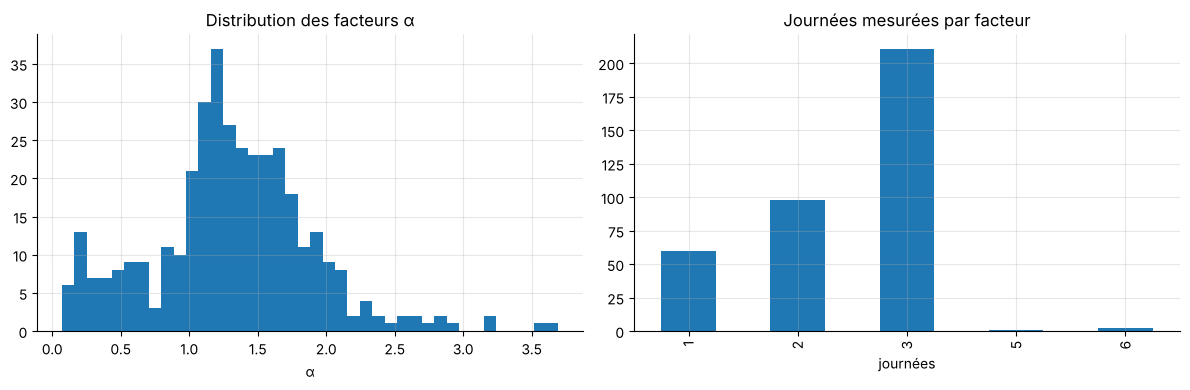

In [4]:
e = sql("SELECT * FROM gold.etalonnage WHERE statut = 'ETALONNE'")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(e["alpha"], bins=40, color="#1f77b4")
ax[0].set(title="Distribution des facteurs α", xlabel="α")
e["n_journees"].value_counts().sort_index().plot.bar(ax=ax[1], color="#1f77b4")
ax[1].set(title="Journées mesurées par facteur", xlabel="journées")
plt.tight_layout()
display(sql("SELECT statut, count(*) AS paires FROM gold.etalonnage GROUP BY 1 ORDER BY 2 DESC"))

**Constat 2.2.** La plupart des facteurs reposent sur 2 à 4 journées, et certains sur une seule.
Le score de confiance en tient compte : −10 points pour un facteur sur une seule journée, −10 si les
journées sources divergent fortement (écart max − min supérieur à 50 % de la médiane).
Les couples sans aucune journée complète ne sont **pas** extrapolés : ils sont listés avec leur statut.

## 3. α dépend-il du type de jour ?

In [5]:
rel = sql("""
    WITH r AS (SELECT j.code_gare, j.ligne, j.type_jour, j.montants / v.validations_moyennes AS r
               FROM _journees j JOIN _vbar v USING (id_zdc, cat_jour_idfm)
               WHERE j.complete AND j.date >= DATE '2022-01-01' AND v.validations_moyennes > 0),
         job AS (SELECT code_gare, ligne, median(r) AS rj FROM r WHERE type_jour = 'JOB' GROUP BY ALL)
    SELECT type_jour, round(median(r / rj), 3) AS alpha_relatif_au_jour_ouvre, count(*) AS journees
    FROM r JOIN job USING (code_gare, ligne) GROUP BY 1 ORDER BY 1""")
rel

,type_jour,alpha_relatif_au_jour_ouvre,journees
0,DIM,1.058,216
1,JOB,1.000,279
2,SAM,1.041,235


**Constat 3.1.** Le facteur d'un samedi ou d'un dimanche est à 4-6 % de celui d'un jour ouvré :
la catégorie de jour IDFM capte déjà l'essentiel de l'effet. Un α unique par gare × ligne suffit,
ce qui évite de le découper en échantillons encore plus petits.

## 4. Profil horaire : quelle part dans chaque tranche ?

In [6]:
parts = sql("""
    SELECT t.code_gare, t.ligne, t.date, t.tranche_horaire, j.type_jour, j.id_zdc, j.cat_jour_idfm,
           t.montants / j.montants AS part
    FROM _tranches t JOIN _journees j USING (code_gare, ligne, date)
    WHERE j.complete AND j.montants > 0""")
idfm = parts.merge(sql("SELECT id_zdc, cat_jour AS cat_jour_idfm, tranche_horaire, pct FROM silver.profils_tranches"),
                   on=["id_zdc", "cat_jour_idfm", "tranche_horaire"])
ligne = parts.merge(parts.groupby(["ligne", "type_jour", "tranche_horaire"])["part"].mean().rename("p").reset_index(),
                    on=["ligne", "type_jour", "tranche_horaire"])
pd.DataFrame({"écart moyen (points de %)": {
    "profil IDFM de la zone (retenu)": (abs(idfm["part"] - idfm["pct"] / 100)).mean() * 100,
    "profil moyen SNCF de la ligne": (abs(ligne["part"] - ligne["p"])).mean() * 100,
}}).round(2)

,écart moyen (points de %)
profil IDFM de la zone (retenu),2.92
profil moyen SNCF de la ligne,3.60


**Constat 4.1.** Le profil horaire IDFM de la zone reproduit la répartition SNCF à moins de 3 points
en moyenne : on le retient, avec le profil moyen SNCF de la ligne comme secours quand la zone n'a pas
de profil publié. (La version en validation croisée stricte du profil de ligne donne 3,6 points.)

## 5. Moduler par les validations du jour ?

Le niveau 3 multiplie α par les validations **du jour** (et non leur moyenne). Les rares journées
SNCF qui tombent dans la fenêtre IDFM permettent de vérifier si les comptages suivent les variations
quotidiennes des validations.

In [7]:
mj = sql("""
    SELECT b.code_gare, b.ligne, b.date, b.mesure, b.alpha_sans_la_journee * b.validations_moyennes AS pred_moyenne,
           b.alpha_sans_la_journee * v.nb_vald AS pred_jour, v.nb_vald / b.validations_moyennes AS indice_jour
    FROM gold.backtest b JOIN silver.correspondance_gares cg USING (code_gare)
    JOIN silver.validations_zone_jour v ON v.id_zdc = cg.id_zdc AND v.jour = b.date""")
print(f"{len(mj)} journées sur {mj['date'].nunique()} dates distinctes")
pd.DataFrame({
    "prédiction avec la moyenne": [(abs(mj.pred_moyenne - mj.mesure) / mj.mesure).median()],
    "prédiction avec les validations du jour": [(abs(mj.pred_jour - mj.mesure) / mj.mesure).median()],
}, index=["erreur médiane"]).style.format("{:.1%}")

87 journées sur 3 dates distinctes


,prédiction avec la moyenne,prédiction avec les validations du jour
erreur médiane,15.4%,27.9%


**Constat 5.1.** Sur ce petit échantillon (3 dates seulement), la moyenne fait mieux que les
validations du jour : on ne peut pas encore prouver que les comptages SNCF suivent les variations
quotidiennes. Le niveau 3 utilise malgré tout les validations du jour, parce qu'un compte *journalier*
doit refléter les grèves, les fêtes et les ponts que montrent les validations (voir §6). Ce choix
sera réévalué quand de nouvelles campagnes SNCF tomberont dans la fenêtre IDFM.

## 6. La météo explique-t-elle les variations journalières ?

Historique Open-Meteo (réanalyse, Paris), comparé à l'écart quotidien des validations du réseau à
leur médiane pour la même catégorie de jour.

R² météo = 0.061 sur 365 jours


,jour,cat,ecart_log,pluie_mm,temperature
79,2025-09-18,JOHV,-0.744199,0.0,18.2
184,2026-01-01,DIJFP,-0.653075,0.0,0.5
183,2025-12-31,JOVS,-0.580619,0.0,0.0
177,2025-12-25,DIJFP,-0.440014,0.1,-0.0
44,2025-08-14,JOVS,-0.417798,0.0,25.6
71,2025-09-10,JOHV,-0.403117,4.4,16.4


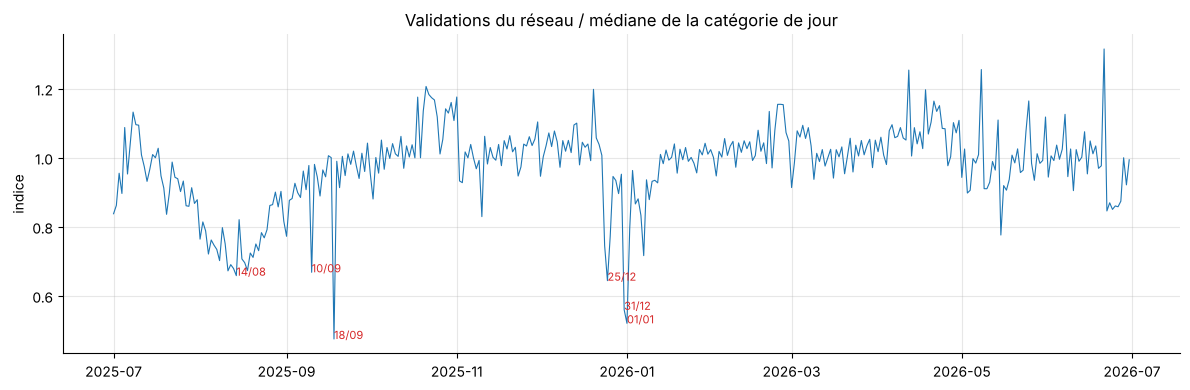

In [8]:
f = silver.latest_files(con, DATA)["openmeteo_historique_paris"]
d = silver.read_json(f.path)["daily"]
meteo = pd.DataFrame({"jour": pd.to_datetime(d["time"]), "temperature": d["temperature_2m_mean"],
                      "pluie_mm": d["precipitation_sum"], "neige_cm": d["snowfall_sum"], "vent": d["wind_speed_10m_max"]})
reseau = sql("""
    WITH n AS (SELECT jour, sum(nb_vald) AS v, any_value(cat_jour_idfm) AS cat FROM silver.validations_zone_jour GROUP BY 1)
    SELECT jour, cat, ln(v / median(v) OVER (PARTITION BY cat)) AS ecart_log FROM n""")
reseau["jour"] = pd.to_datetime(reseau["jour"])
df = reseau.merge(meteo, on="jour").dropna()
X = np.column_stack([np.ones(len(df)), df.pluie_mm.clip(0, 30), (df.pluie_mm > 5), df.neige_cm, df.temperature, df.vent])
beta, *_ = np.linalg.lstsq(X.astype(float), df.ecart_log, rcond=None)
r2 = 1 - ((df.ecart_log - X @ beta) ** 2).sum() / ((df.ecart_log - df.ecart_log.mean()) ** 2).sum()
print(f"R² météo = {r2:.3f} sur {len(df)} jours")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.jour, np.exp(df.ecart_log), lw=.8, color="#1f77b4")
for _, r in df.nsmallest(6, "ecart_log").iterrows():
    ax.annotate(r.jour.strftime("%d/%m"), (r.jour, np.exp(r.ecart_log)), fontsize=8, color="#d62728")
ax.set(title="Validations du réseau / médiane de la catégorie de jour", ylabel="indice")
plt.tight_layout()
df.nsmallest(6, "ecart_log")[["jour", "cat", "ecart_log", "pluie_mm", "temperature"]]

**Constat 6.1.** La météo explique environ 6 % des écarts journaliers. Les plus fortes baisses
sont des jours de grève (septembre 2025) et de fêtes (Noël, 31 décembre, mi-août), pas des jours de
pluie. On n'ajoute donc **pas** de modèle météo à l'extrapolation : il compliquerait le calcul sans
le rendre plus juste. La météo reste collectée pour la prédiction horaire de l'étape 4.

## 7. Résultat : le compte officiel

,methode,lignes,voyageurs,score
0,EXTRAPOLE,221049,244948945,58.1
1,MESURE,5526,6012708,88.0
2,RECONCILIE_IDFM,668295,816334978,78.1


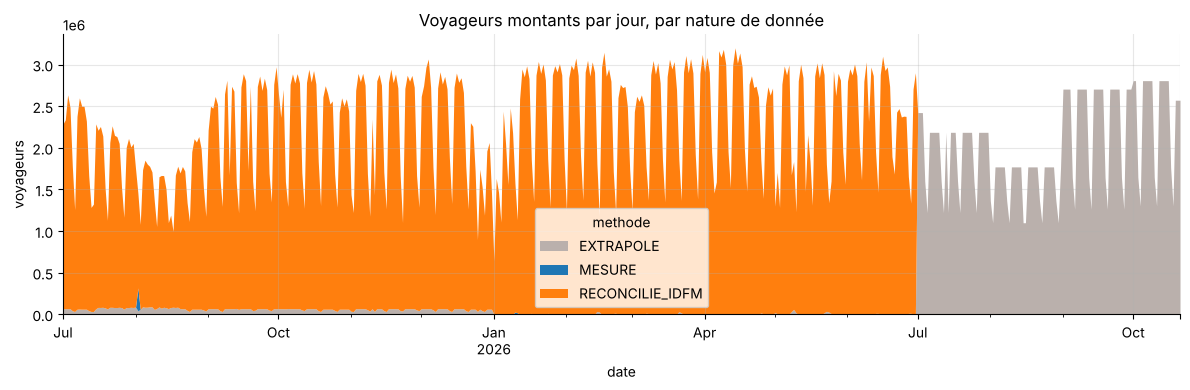

In [9]:
compo = sql("""SELECT methode, count(*) AS lignes, sum(voyageurs)::BIGINT AS voyageurs, round(avg(score_confiance), 1) AS score
                 FROM gold.compte_officiel GROUP BY 1 ORDER BY 1""")
display(compo)
jour = sql("""SELECT date, methode, sum(voyageurs) AS voyageurs FROM gold.compte_officiel
                WHERE date >= (SELECT min(jour) FROM silver.validations_zone_jour) GROUP BY ALL""")
jour.pivot_table(index="date", columns="methode", values="voyageurs", fill_value=0).plot.area(
    figsize=(12, 4), color={"MESURE": "#1f77b4", "RECONCILIE_IDFM": "#ff7f0e", "EXTRAPOLE": "#bab0ac"}, lw=0)
plt.title("Voyageurs montants par jour, par nature de donnée"); plt.ylabel("voyageurs"); plt.tight_layout()

**Lecture.** Jusqu'à la fin de la fenêtre IDFM, le compte suit les validations du jour (creux des grèves
et des fêtes visibles). Ensuite, il est extrapolé à partir du même mois de l'année précédente : le profil
est plus régulier et le score de confiance plafonne à 60.

## 8. Validation croisée

846 journées · erreur médiane 9.6% · WAPE 16.1%


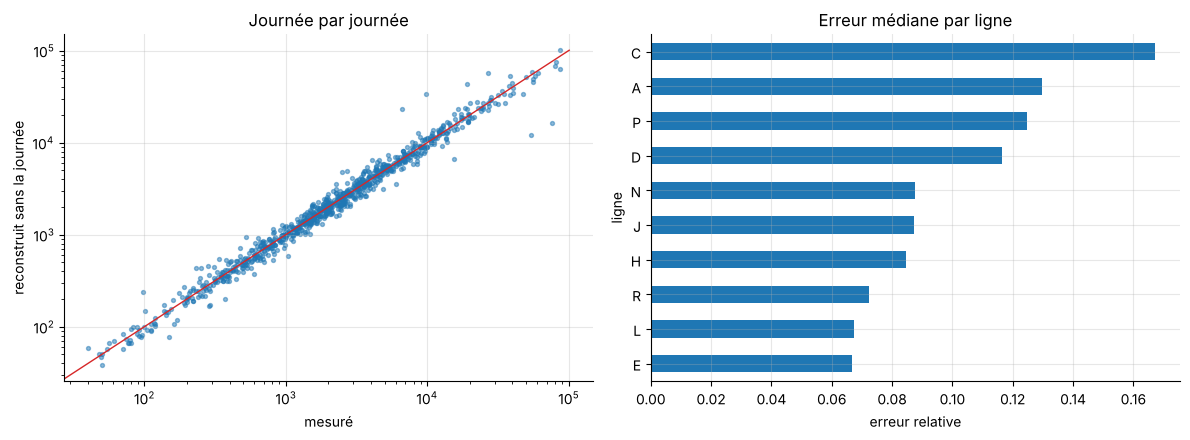

In [10]:
bt = sql("SELECT * FROM gold.backtest")
print(f"{len(bt)} journées · erreur médiane {bt.erreur_relative.median():.1%} · "
      f"WAPE {abs(bt.prediction - bt.mesure).sum() / bt.mesure.sum():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(bt.mesure, bt.prediction, s=8, alpha=.5)
lim = bt[["mesure", "prediction"]].max().max()
ax[0].plot([0, lim], [0, lim], color="#d62728", lw=1)
ax[0].set(xscale="log", yscale="log", xlabel="mesuré", ylabel="reconstruit sans la journée", title="Journée par journée")
bt.groupby("ligne")["erreur_relative"].median().sort_values().plot.barh(ax=ax[1], color="#1f77b4")
ax[1].set(title="Erreur médiane par ligne", xlabel="erreur relative")
plt.tight_layout()

**Conclusion.**
- Une journée reconstruite s'écarte de la mesure de **10 % en médiane**. Les grosses erreurs
  viennent de gares mesurées une seule fois ou très irrégulièrement, déjà pénalisées dans le score.
- Le niveau 2 (train supprimé) attend des comptages par train. Il sera rebranché sur l'offre
  réalisée PRIM si la SNCF publie un jour ce niveau de détail.
- Chaque chiffre du compte garde ses composants (α, validations, part de la tranche, comptages source) :
  le Dashboard 3 et la table `gold.compte_officiel` permettent de le refaire à la main.